# Optimisation d'hyperparamètres avec Ray Tune

## 1. Mise en œuvre de Ray Tune

Ray Tune permet d'automatiser la recherche d'hyperparamètres
en exécutant plusieurs configurations d'un modèle et en comparant
leurs performances.

Dans ce notebook, nous allons :
- définir un espace de recherche ;
- comparer quatre stratégies de recherche (aléatoire, ASHA, PBT, OptunaSearch) avec **le même budget d'essais** ;
- mesurer la **durée totale** de chaque recherche ;
- récupérer la meilleure configuration de chaque méthode ;
- évaluer ces configurations sur le jeu de test, avec plusieurs graines aléatoires.

In [2]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import time
import numpy as np
import pandas as pd
import ray
from ray import tune, train
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist

In [3]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print(X_train.shape)
print(X_test.shape)

(60000, 28, 28)
(10000, 28, 28)


## 2. Exploration, vérification et préparation des données

### EDA

In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Dimensions et structure des données
print("Train :", X_train.shape, y_train.shape)
print("Test  :", X_test.shape, y_test.shape)
print("Classes :", np.unique(y_train))
print("Valeur minimale des pixels :", X_train.min())
print("Valeur maximale des pixels :", X_train.max())


Train : (60000, 28, 28) (60000,)
Test  : (10000, 28, 28) (10000,)
Classes : [0 1 2 3 4 5 6 7 8 9]
Valeur minimale des pixels : 0.0
Valeur maximale des pixels : 1.0



Distribution des classes :
0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64


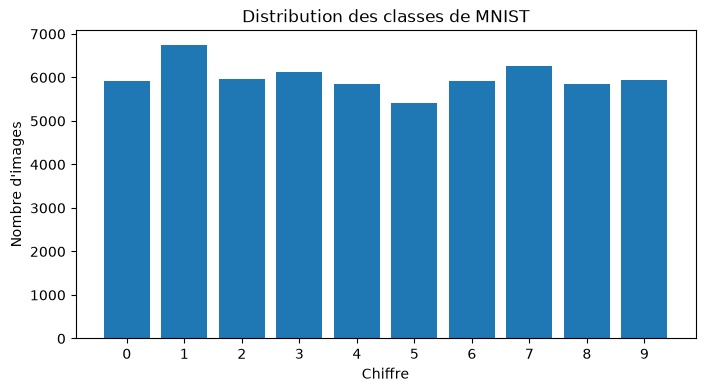

In [5]:
# 2. Distribution des chiffres
distribution = pd.Series(y_train).value_counts().sort_index()
print("\nDistribution des classes :")
print(distribution)

plt.figure(figsize=(8, 4))
plt.bar(distribution.index, distribution.values)
plt.xlabel("Chiffre")
plt.ylabel("Nombre d'images")
plt.title("Distribution des classes de MNIST")
plt.xticks(range(10))
plt.show()

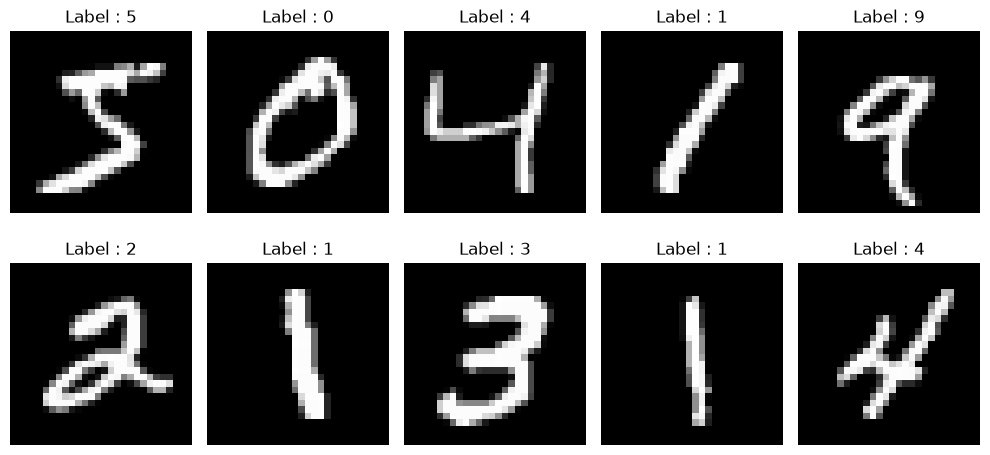

In [6]:
# 3. Visualisation de quelques images
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label : {y_train[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Nettoyage des données

In [7]:
# 4. Vérification de la qualité des données
print("Valeurs manquantes :", np.isnan(X_train).sum())
print("Valeurs infinies :", np.isinf(X_train).sum())
print("Labels valides :", np.isin(y_train, range(10)).all())
print("Dimensions des images :", X_train.shape[1:])
print("Données d'entraînement finies :", np.isfinite(X_train).all())

Valeurs manquantes : 0
Valeurs infinies : 0
Labels valides : True
Dimensions des images : (28, 28)
Données d'entraînement finies : True


### Statistiques descriptives par image (exploration)

Nous calculons deux statistiques simples par image (intensité moyenne et écart-type des pixels)
pour mieux comprendre les données. **Elles ne sont pas utilisées par le modèle** :
le réseau reçoit directement les 784 pixels de chaque image.

In [8]:
# Chaque image contient 28 × 28 = 784 pixels
X_train_flat = X_train.reshape(X_train.shape[0], -1)

# Deux caractéristiques dérivées par image
mean_intensity = X_train_flat.mean(axis=1)
std_intensity = X_train_flat.std(axis=1)

features_df = pd.DataFrame({
    "label": y_train,
    "intensite_moyenne": mean_intensity,
    "ecart_type": std_intensity
})
print("Aperçu des caractéristiques dérivées :")
display(features_df.head())

Aperçu des caractéristiques dérivées :


,label,intensite_moyenne,ecart_type
0,5,0.137680,0.312348
1,0,0.155537,0.328969
2,4,0.097254,0.257175
3,1,0.085709,0.259133
4,9,0.116116,0.291652


In [9]:
print("\nStatistiques descriptives :")
display(features_df[["intensite_moyenne", "ecart_type"]].describe())



Statistiques descriptives :


,intensite_moyenne,ecart_type
count,60000.000000,60000.000000
mean,0.130660,0.301312
std,0.043299,0.047611
min,0.025440,0.124900
25%,0.099330,0.268836
50%,0.127386,0.302826
75%,0.157873,0.334787
max,0.397574,0.467293


<Figure size 900x400 with 0 Axes>

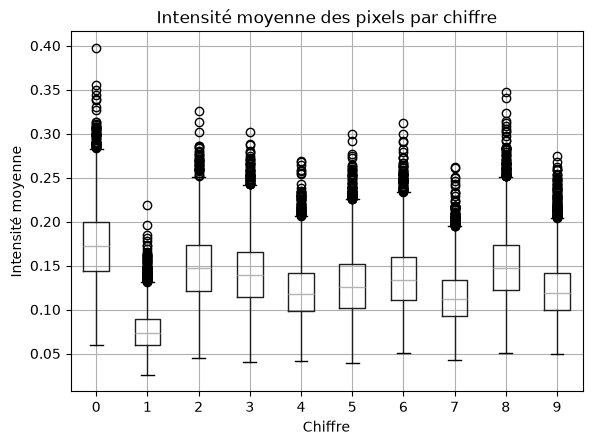

In [10]:
# Comparaison de l'intensité moyenne selon le chiffre
plt.figure(figsize=(9, 4))
features_df.boxplot(column="intensite_moyenne", by="label")
plt.title("Intensité moyenne des pixels par chiffre")
plt.suptitle("")
plt.xlabel("Chiffre")
plt.ylabel("Intensité moyenne")
plt.show()

## 3. Configuration de l'expérience

Pour que la comparaison soit équitable, **toutes les méthodes utilisent le même budget** :
le même nombre d'essais (`NUM_SAMPLES`), le même nombre d'époques (`EPOCHS`), la même
concurrence (2 essais en parallèle) et la même graine d'initialisation (`SEED`).


In [11]:
NUM_SAMPLES = 8      # nombre d'essais, identique pour TOUTES les méthodes
EPOCHS = 10          # époques par essai
N_SEEDS = 3          # nombre de graines pour l'évaluation finale sur le test
SEED = 42            # graine d'initialisation pendant les recherches

NOMS = ["Recherche aléatoire", "ASHA", "PBT", "OptunaSearch"]
durees = {}               # durée totale de chaque recherche (secondes)
resultats_methodes = {}   # objets ResultGrid de chaque méthode

In [12]:
ray.init(
    num_cpus=2,
    log_to_driver=False,
    ignore_reinit_error=True
)

2026-10-10 06:23:33,352	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html
2026-10-10 06:23:39,755	INFO worker.py:2033 -- Started a local Ray instance.


Python version:,3.11.4
Ray version:,2.59.0


In [13]:
X_train_ref = ray.put(X_train)
y_train_ref = ray.put(y_train)

### Modèle, fonction d'entraînement et espace de recherche

L'espace de recherche est volontairement plus large que quelques valeurs fixes :
la taille de la couche cachée, le dropout (continu), le learning rate (échelle logarithmique)
et la taille de batch varient sur des plages étendues. Avec un espace trop petit,
aucune méthode intelligente ne peut montrer d'avantage sur une recherche aléatoire.

In [14]:
def construire_modele(config):
    modele = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(config["units"], activation="relu"),
        tf.keras.layers.Dropout(config["dropout"]),
        tf.keras.layers.Dense(10, activation="softmax")
    ])
    modele.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=config["learning_rate"]),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return modele


def train_model(config):
    tf.keras.utils.set_random_seed(SEED)
    X_tr = ray.get(X_train_ref)
    y_tr = ray.get(y_train_ref)

    model = construire_modele(config)

    for epoch in range(EPOCHS):
        history = model.fit(
            X_tr,
            y_tr,
            validation_split=0.1,
            epochs=1,
            batch_size=config["batch_size"],
            verbose=0
        )

        tune.report({
            "accuracy": history.history["val_accuracy"][0],
            "epoch": epoch + 1
        })

In [15]:
search_space = {
    "units": tune.choice([32, 64, 128, 256, 512]),
    "dropout": tune.uniform(0.1, 0.5),
    "learning_rate": tune.loguniform(1e-4, 1e-2),
    "batch_size": tune.choice([32, 64, 128, 256])
}


def config_tune(**kwargs):
    """TuneConfig commun à toutes les méthodes (même budget, même concurrence).
    trial_dirname_creator raccourcit les noms de dossiers (limite de 260 caractères sous Windows)."""
    return tune.TuneConfig(
        num_samples=NUM_SAMPLES,
        max_concurrent_trials=2,
        trial_dirname_creator=lambda trial: trial.trial_id,
        **kwargs
    )

## 4. Recherche aléatoire (référence)

Chaque essai tire une configuration au hasard dans l'espace de recherche et s'entraîne
jusqu'au bout. C'est la référence à battre.

In [16]:
tuner = tune.Tuner(
    train_model,
    param_space=search_space,
    tune_config=config_tune()
)

t0 = time.perf_counter()
results = tuner.fit()
durees["Recherche aléatoire"] = time.perf_counter() - t0
resultats_methodes["Recherche aléatoire"] = results

print(f"Durée totale : {durees['Recherche aléatoire']:.0f} s")

2026-10-10 06:34:52,213	INFO tune.py:1007 -- Wrote the latest version of all result files and experiment state to 'C:/Users/HP/ray_results/train_model_2026-10-10_06-24-03' in 0.0472s.
2026-10-10 06:34:52,229	INFO tune.py:1039 -- Total run time: 648.36 seconds (648.12 seconds for the tuning loop).


Durée totale : 648 s


In [17]:
best_result = results.get_best_result(metric="accuracy", mode="max")

print("Meilleurs hyperparamètres (recherche aléatoire) :")
for param, valeur in best_result.config.items():
    print(f"{param} : {valeur}")

print(f"\nAccuracy de validation : {best_result.metrics['accuracy']:.2%}")

Meilleurs hyperparamètres (recherche aléatoire) :
units : 512
dropout : 0.4619924276526278
learning_rate : 0.00260167755781301
batch_size : 128

Accuracy de validation : 98.38%


## 5. Optimisation avec ASHA

ASHA arrête tôt les essais peu prometteurs pour réserver le calcul aux meilleurs.
Le gain attendu porte sur la **durée totale** de la recherche.

In [18]:
from ray.tune.schedulers import ASHAScheduler

asha_scheduler = ASHAScheduler(
    metric="accuracy",
    mode="max",
    max_t=EPOCHS,
    grace_period=2,
    reduction_factor=2
)

tuner_asha = tune.Tuner(
    train_model,
    param_space=search_space,
    tune_config=config_tune(scheduler=asha_scheduler)
)

t0 = time.perf_counter()
results_asha = tuner_asha.fit()
durees["ASHA"] = time.perf_counter() - t0
resultats_methodes["ASHA"] = results_asha

print(f"Durée totale : {durees['ASHA']:.0f} s")

2026-10-10 06:39:54,082	INFO tune.py:1007 -- Wrote the latest version of all result files and experiment state to 'C:/Users/HP/ray_results/train_model_2026-10-10_06-35-27' in 0.0942s.
2026-10-10 06:39:54,104	INFO tune.py:1039 -- Total run time: 266.60 seconds (266.42 seconds for the tuning loop).


Durée totale : 267 s


In [19]:
best_asha = results_asha.get_best_result(metric="accuracy", mode="max")

print("Meilleurs hyperparamètres avec ASHA :")
for param, valeur in best_asha.config.items():
    print(f"{param} : {valeur}")
print(f"Accuracy de validation : {best_asha.metrics['accuracy']:.2%}")

Meilleurs hyperparamètres avec ASHA :
units : 128
dropout : 0.20449012120489016
learning_rate : 0.0016675807390451182
batch_size : 64
Accuracy de validation : 98.18%


## 6. Optimisation avec PBT

PBT entraîne une population d'essais et, régulièrement, remplace les plus faibles par une copie
mutée des meilleurs. Le nombre de neurones (`units`) n'est pas muté : changer la forme du réseau
rendrait les poids copiés incompatibles. Si un essai est remplacé par un essai ayant un autre `units`,
`reset_config` renvoie `False` et Ray reconstruit alors le modèle.

In [20]:
import os
from ray.tune.schedulers import PopulationBasedTraining


class MNISTTrainable(tune.Trainable):
    def setup(self, config):
        tf.keras.utils.set_random_seed(SEED)
        self.X_train = ray.get(X_train_ref)
        self.y_train = ray.get(y_train_ref)
        self.epoch = 0
        self.model = construire_modele(config)

    def step(self):
        history = self.model.fit(
            self.X_train, self.y_train,
            validation_split=0.1,
            epochs=1,
            batch_size=self.config["batch_size"],
            verbose=0
        )
        self.epoch += 1
        return {
            "accuracy": float(history.history["val_accuracy"][0]),
            "training_iteration": self.epoch
        }

    def reset_config(self, new_config):
        # Si la structure du réseau change, on ne peut pas réutiliser le modèle :
        # on demande à Ray de reconstruire l'essai (setup est rappelé).
        if new_config["units"] != self.config["units"]:
            return False
        self.config = new_config
        for layer in self.model.layers:
            if isinstance(layer, tf.keras.layers.Dropout):
                layer.rate = new_config["dropout"]
        self.model.optimizer.learning_rate.assign(new_config["learning_rate"])
        return True

    def save_checkpoint(self, checkpoint_dir):
        self.model.save_weights(os.path.join(checkpoint_dir, "model.weights.h5"))
        return checkpoint_dir

    def load_checkpoint(self, checkpoint_dir):
        self.model.load_weights(os.path.join(checkpoint_dir, "model.weights.h5"))


pbt_scheduler = PopulationBasedTraining(
    time_attr="training_iteration",
    metric="accuracy",
    mode="max",
    perturbation_interval=2,
    hyperparam_mutations={
        "dropout": tune.uniform(0.1, 0.5),
        "learning_rate": tune.loguniform(1e-4, 1e-2),
        "batch_size": [32, 64, 128, 256]
    }
)

pbt_tuner = tune.Tuner(
    MNISTTrainable,
    param_space=search_space,
    tune_config=config_tune(scheduler=pbt_scheduler),
    run_config=tune.RunConfig(stop={"training_iteration": EPOCHS})
)

t0 = time.perf_counter()
results_pbt = pbt_tuner.fit()
durees["PBT"] = time.perf_counter() - t0
resultats_methodes["PBT"] = results_pbt

print(f"Durée totale : {durees['PBT']:.0f} s")
print(f"Essais : {len(results_pbt)} | essais en erreur : {len(results_pbt.errors)}")

2026-10-10 06:44:39,331	INFO pbt.py:741 -- [pbt]: no checkpoint for trial MNISTTrainable_8be1b_00000. Skip exploit for Trial MNISTTrainable_8be1b_00001
2026-10-10 06:45:13,734	INFO pbt.py:903 -- 

[PopulationBasedTraining] [Exploit] Cloning trial 8be1b_00000 (score = 0.982667) into trial 8be1b_00001 (score = 0.980667)

2026-10-10 06:45:13,756	INFO pbt.py:930 -- 

[PopulationBasedTraining] [Explore] Perturbed the hyperparameter config of trial8be1b_00001:
dropout : 0.3400913559757054 --- (* 0.8) --> 0.2720730847805643
learning_rate : 0.0017466387276912866 --- (* 0.8) --> 0.0013973109821530294
batch_size : 128 --- (shift right) --> 256

2026-10-10 06:45:54,559	INFO pbt.py:741 -- [pbt]: no checkpoint for trial MNISTTrainable_8be1b_00001. Skip exploit for Trial MNISTTrainable_8be1b_00002
2026-10-10 06:46:01,335	INFO pbt.py:741 -- [pbt]: no checkpoint for trial MNISTTrainable_8be1b_00001. Skip exploit for Trial MNISTTrainable_8be1b_00002
2026-10-10 06:46:11,191	INFO pbt.py:741 -- [pbt]: no 

Durée totale : 576 s
Essais : 8 | essais en erreur : 0


In [21]:
best_pbt = results_pbt.get_best_result(metric="accuracy", mode="max")

print("Meilleurs hyperparamètres avec PBT :")
for param, valeur in best_pbt.config.items():
    print(f"{param} : {valeur}")
print(f"Accuracy de validation : {best_pbt.metrics['accuracy']:.2%}")

Meilleurs hyperparamètres avec PBT :
units : 256
dropout : 0.2720730847805643
learning_rate : 0.0013973109821530294
batch_size : 256
Accuracy de validation : 98.42%


## 7. OptunaSearch dans Ray Tune

Ray Tune orchestre les essais ; OptunaSearch choisit les configurations à tester en tenant compte
des résultats déjà obtenus. Cette expérience réutilise le même modèle TensorFlow, la même fonction
`train_model`, le même espace de recherche et le même budget que les méthodes précédentes.

In [22]:
from ray.tune.search.optuna import OptunaSearch

optuna_search = OptunaSearch(
    metric="accuracy",
    mode="max",
    seed=SEED
)

tuner_optuna = tune.Tuner(
    train_model,
    param_space=search_space,
    tune_config=config_tune(search_alg=optuna_search)
)

t0 = time.perf_counter()
results_optuna = tuner_optuna.fit()
durees["OptunaSearch"] = time.perf_counter() - t0
resultats_methodes["OptunaSearch"] = results_optuna

print(f"Durée totale : {durees['OptunaSearch']:.0f} s")

best_optuna_ray = results_optuna.get_best_result(metric="accuracy", mode="max")

print("Meilleurs hyperparamètres avec OptunaSearch + Ray Tune :")
for param, valeur in best_optuna_ray.config.items():
    print(f"{param} : {valeur}")
print(f"Accuracy de validation : {best_optuna_ray.metrics['accuracy']:.2%}")

2026-10-10 07:16:30,120	INFO tune.py:1007 -- Wrote the latest version of all result files and experiment state to 'C:/Users/HP/ray_results/train_model_2026-10-10_07-04-35' in 0.0887s.
2026-10-10 07:16:30,136	INFO tune.py:1039 -- Total run time: 714.28 seconds (714.10 seconds for the tuning loop).


Durée totale : 714 s
Meilleurs hyperparamètres avec OptunaSearch + Ray Tune :
units : 256
dropout : 0.3056937753654446
learning_rate : 0.0015304852121831463
batch_size : 64
Accuracy de validation : 98.13%


## 8. Comparaison des quatre méthodes

Le tableau rapporte l'accuracy de **validation** (utilisée pour choisir la configuration), la **durée totale
de la recherche** (et non celle du seul meilleur essai) et le nombre d'essais en erreur.
Les axes des graphiques d'accuracy sont zoomés : les écarts réels sont petits.

,Méthode,Essais,Essais en erreur,Accuracy validation (%),Durée totale recherche (s),Durée meilleur essai (s),Unités,Dropout,Learning rate,Batch size
0,Recherche aléatoire,8,0,98.38,648.5,88.6,512,0.462,0.002602,128
1,ASHA,8,0,98.18,266.8,100.6,128,0.204,0.001668,64
2,PBT,8,0,98.42,575.9,156.6,256,0.272,0.001397,256
3,OptunaSearch,8,0,98.13,714.5,191.1,256,0.306,0.001530,64


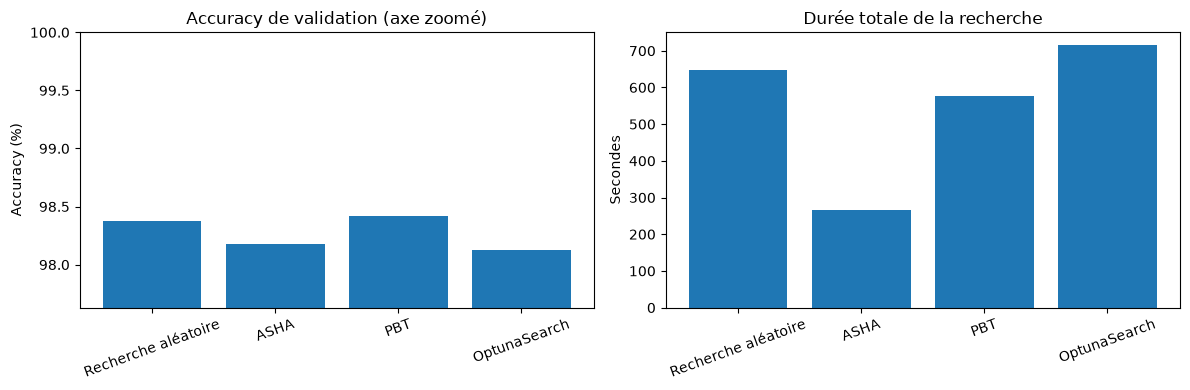

In [23]:
def extraire_resultat(nom, resultats):
    meilleur = resultats.get_best_result(metric="accuracy", mode="max")
    return {
        "Méthode": nom,
        "Essais": len(resultats),
        "Essais en erreur": len(resultats.errors),
        "Accuracy validation (%)": round(float(meilleur.metrics["accuracy"]) * 100, 2),
        "Durée totale recherche (s)": round(durees[nom], 1),
        "Durée meilleur essai (s)": round(float(meilleur.metrics.get("time_total_s", 0)), 1),
        "Unités": meilleur.config["units"],
        "Dropout": round(float(meilleur.config["dropout"]), 3),
        "Learning rate": float(meilleur.config["learning_rate"]),
        "Batch size": meilleur.config["batch_size"]
    }


comparaison = pd.DataFrame([extraire_resultat(n, resultats_methodes[n]) for n in NOMS])
display(comparaison)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(comparaison["Méthode"], comparaison["Accuracy validation (%)"])
bas = comparaison["Accuracy validation (%)"].min() - 0.5
axes[0].set_ylim(bas, 100)
axes[0].set_title("Accuracy de validation (axe zoomé)")
axes[0].set_ylabel("Accuracy (%)")
axes[0].tick_params(axis="x", rotation=20)

axes[1].bar(comparaison["Méthode"], comparaison["Durée totale recherche (s)"])
axes[1].set_title("Durée totale de la recherche")
axes[1].set_ylabel("Secondes")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### Courbes de convergence

Pour chaque méthode, on trace la meilleure accuracy de validation atteinte au fil des essais.
Les essais sont classés selon leur **identifiant** (`trial_id`), qui suit l'ordre de création des essais.
Avec 2 essais en parallèle, cet ordre reste approximatif. Pour ASHA, les essais arrêtés tôt
sont représentés par leur dernière valeur, obtenue après peu d'époques.

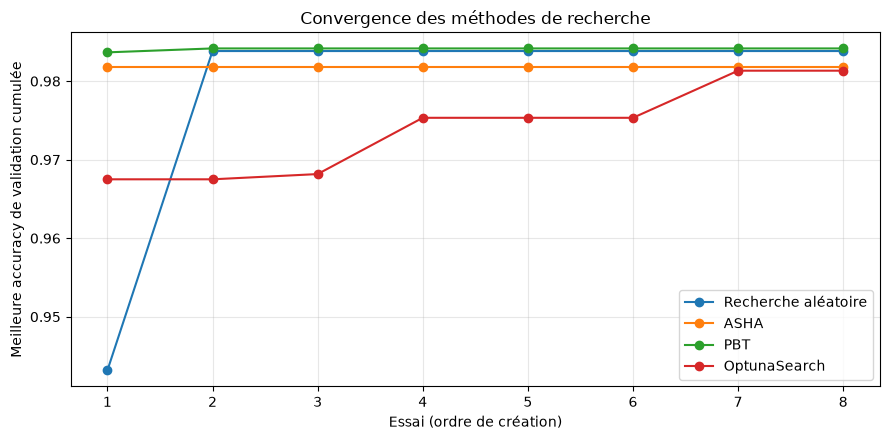

In [24]:
def accuracies_par_essai(resultats):
    df = resultats.get_dataframe()
    col = "accuracy" if "accuracy" in df.columns else "metrics/accuracy"
    if col not in df.columns:
        print("Colonnes disponibles :", df.columns.tolist())
        raise KeyError("La colonne d'accuracy est introuvable dans les résultats Ray Tune.")
    df = df.dropna(subset=[col]).sort_values("trial_id").reset_index(drop=True)
    return df, col


plt.figure(figsize=(9, 4.5))
for nom in NOMS:
    df_m, col = accuracies_par_essai(resultats_methodes[nom])
    plt.plot(range(1, len(df_m) + 1), df_m[col].cummax(), marker="o", label=nom)

plt.xlabel("Essai (ordre de création)")
plt.ylabel("Meilleure accuracy de validation cumulée")
plt.title("Convergence des méthodes de recherche")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Sensibilité aux hyperparamètres (OptunaSearch)

Les importances calculées par `optuna.importance` demandent un objet `study` Optuna, que Ray Tune
ne fournit pas directement. À la place, on mesure la corrélation de Spearman entre chaque hyperparamètre
et l'accuracy de validation sur les essais d'OptunaSearch.


Nombre d'essais utilisés : 8


,Corrélation de Spearman avec l'accuracy
batch_size,0.049417
dropout,0.095238
learning_rate,0.190476
units,0.793725


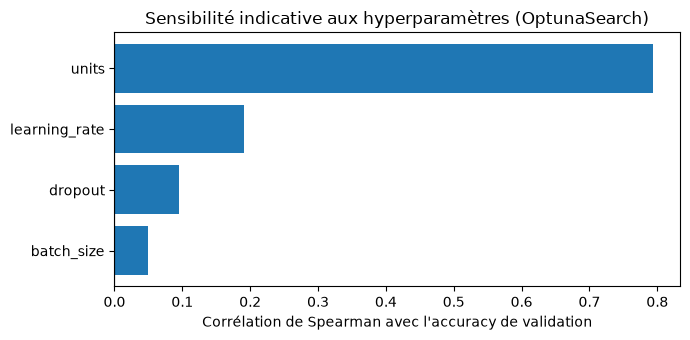

In [25]:
df_opt, col = accuracies_par_essai(results_optuna)
params = [c for c in df_opt.columns if c.startswith("config/")]

correlations = (
    df_opt[params]
    .corrwith(df_opt[col], method="spearman")
    .rename(lambda c: c.replace("config/", ""))
    .sort_values()
)
print(f"Nombre d'essais utilisés : {len(df_opt)}")
display(correlations.to_frame("Corrélation de Spearman avec l'accuracy"))

plt.figure(figsize=(7, 3.5))
plt.barh(correlations.index, correlations.values)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Corrélation de Spearman avec l'accuracy de validation")
plt.title("Sensibilité indicative aux hyperparamètres (OptunaSearch)")
plt.tight_layout()
plt.show()

## 9. Évaluation finale sur le jeu de test

La validation sert à **choisir** une configuration ; le jeu de test, jamais utilisé pendant les
recherches, sert à **mesurer** sa qualité. Pour chaque méthode, on réentraîne la meilleure configuration
avec plusieurs graines différentes (`N_SEEDS`) et on rapporte la moyenne et l'écart-type de l'accuracy de test.

Pour PBT, la configuration retenue est la configuration finale de l'essai gagnant ; elle est réentraînée
depuis zéro, alors que PBT a en réalité fait évoluer les hyperparamètres pendant l'entraînement.
Le résultat peut donc différer légèrement de celui observé pendant la recherche.

Recherche aléatoire : test = 98.09 % ± 0.13 (graines : 3)
ASHA : test = 97.77 % ± 0.08 (graines : 3)
PBT : test = 98.00 % ± 0.05 (graines : 3)
OptunaSearch : test = 97.93 % ± 0.07 (graines : 3)


,Méthode,Accuracy validation (%),Accuracy test moyenne (%),Écart-type test (%)
0,Recherche aléatoire,98.38,98.09,0.13
1,ASHA,98.18,97.77,0.08
2,PBT,98.42,98.00,0.05
3,OptunaSearch,98.13,97.93,0.07


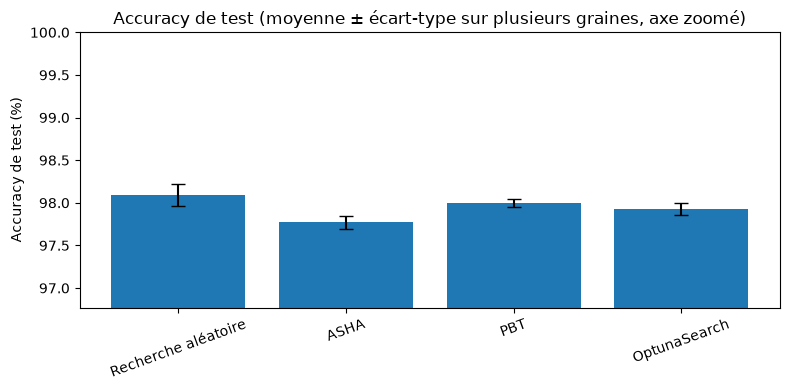

In [26]:
def evaluer_sur_test(config, n_seeds=N_SEEDS):
    scores = []
    for graine in range(n_seeds):
        tf.keras.utils.set_random_seed(100 + graine)
        modele = construire_modele(config)
        modele.fit(
            X_train, y_train,
            validation_split=0.1,
            epochs=EPOCHS,
            batch_size=config["batch_size"],
            verbose=0
        )
        _, acc = modele.evaluate(X_test, y_test, verbose=0)
        scores.append(acc)
    return np.array(scores) * 100


lignes = []
for nom in NOMS:
    meilleur = resultats_methodes[nom].get_best_result(metric="accuracy", mode="max")
    scores = evaluer_sur_test(meilleur.config)
    lignes.append({
        "Méthode": nom,
        "Accuracy validation (%)": round(float(meilleur.metrics["accuracy"]) * 100, 2),
        "Accuracy test moyenne (%)": round(float(scores.mean()), 2),
        "Écart-type test (%)": round(float(scores.std()), 2),
    })
    print(f"{nom} : test = {scores.mean():.2f} % ± {scores.std():.2f} (graines : {N_SEEDS})")

final_df = pd.DataFrame(lignes)
display(final_df)

plt.figure(figsize=(8, 4))
plt.bar(final_df["Méthode"], final_df["Accuracy test moyenne (%)"],
        yerr=final_df["Écart-type test (%)"], capsize=5)
plt.ylim(final_df["Accuracy test moyenne (%)"].min() - 1, 100)
plt.ylabel("Accuracy de test (%)")
plt.title("Accuracy de test (moyenne ± écart-type sur plusieurs graines, axe zoomé)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 10. Conclusion expérimentale

La cellule ci-dessous résume les chiffres **de cette exécution** et indique si les écarts observés
dépassent le bruit entre graines. Les conclusions qualitatives (quelle méthode choisir, pourquoi)
doivent s'appuyer sur ces chiffres et sur les graphiques de convergence et de durée.

In [27]:
tri = final_df.sort_values("Accuracy test moyenne (%)", ascending=False).reset_index(drop=True)
premier, second = tri.iloc[0], tri.iloc[1]
ecart = premier["Accuracy test moyenne (%)"] - second["Accuracy test moyenne (%)"]
bruit = max(premier["Écart-type test (%)"], second["Écart-type test (%)"])

plus_rapide = comparaison.sort_values("Durée totale recherche (s)").iloc[0]
erreurs = int(comparaison["Essais en erreur"].sum())

print(f"Budget : {NUM_SAMPLES} essais par méthode, {EPOCHS} époques, {N_SEEDS} graines pour le test.")
print(f"Meilleure accuracy de test moyenne : {premier['Méthode']} "
      f"({premier['Accuracy test moyenne (%)']:.2f} %).")
print(f"Écart avec la deuxième ({second['Méthode']}) : {ecart:.2f} point(s) ; "
      f"écart-type entre graines : {bruit:.2f} point(s).")
if ecart > bruit:
    print("-> L'écart dépasse le bruit entre graines : la différence est plausible, "
          "mais reste à confirmer avec plus d'essais.")
else:
    print("-> L'écart est du même ordre que le bruit entre graines : "
          "on ne peut pas affirmer qu'une méthode est meilleure sur la précision.")
print(f"Recherche la plus rapide : {plus_rapide['Méthode']} "
      f"({plus_rapide['Durée totale recherche (s)']:.0f} s au total).")
print(f"Essais en erreur (toutes méthodes) : {erreurs}"
      + (" -> à signaler dans l'interprétation." if erreurs else "."))

Budget : 8 essais par méthode, 10 époques, 3 graines pour le test.
Meilleure accuracy de test moyenne : Recherche aléatoire (98.09 %).
Écart avec la deuxième (PBT) : 0.09 point(s) ; écart-type entre graines : 0.13 point(s).
-> L'écart est du même ordre que le bruit entre graines : on ne peut pas affirmer qu'une méthode est meilleure sur la précision.
Recherche la plus rapide : ASHA (267 s au total).
Essais en erreur (toutes méthodes) : 0.
